In [ ]:
!pip -q install fastapi uvicorn python-multipart pillow

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import files
import time, json, os

model = tf.keras.applications.MobileNetV2(
    weights="imagenet",
    include_top=True,
    input_shape=(224, 224, 3)
)

print("VisionPort photo model loaded!")
print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

14536120/14536120 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
VisionPort photo model loaded!
TensorFlow: 2.21.0
GPU devices: []


Saving Ginger Cat Amid Greenery.png to Ginger Cat Amid Greenery.png


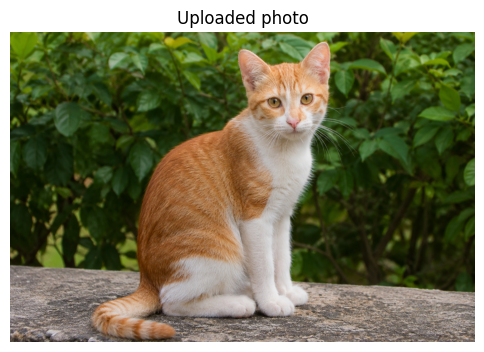

35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
VisionPort predictions:
tiger cat: 45.78%
Egyptian cat: 26.17%
tabby: 5.27%

Inference latency: 1303.3 ms


In [ ]:
def predict_photo(image):
    image = image.convert("RGB").resize((224, 224))
    arr = np.array(image, dtype=np.float32)
    arr = tf.keras.applications.mobilenet_v2.preprocess_input(arr)
    arr = np.expand_dims(arr, axis=0)

    start = time.perf_counter()
    scores = model.predict(arr, verbose=0)
    latency_ms = (time.perf_counter() - start) * 1000

    decoded = tf.keras.applications.mobilenet_v2.decode_predictions(
        scores, top=3
    )[0]

    results = [
        {"label": label.replace("_", " "), "confidence": float(score)}
        for _, label, score in decoded
    ]

    return results, latency_ms

uploaded = files.upload()

if uploaded:
    filename = next(iter(uploaded))
    photo = Image.open(filename).convert("RGB")

    plt.figure(figsize=(6, 5))
    plt.imshow(photo)
    plt.axis("off")
    plt.title("Uploaded photo")
    plt.show()

    results, latency = predict_photo(photo)

    print("VisionPort predictions:")
    for item in results:
        print(f"{item['label']}: {item['confidence']:.2%}")

    print(f"\nInference latency: {latency:.1f} ms")

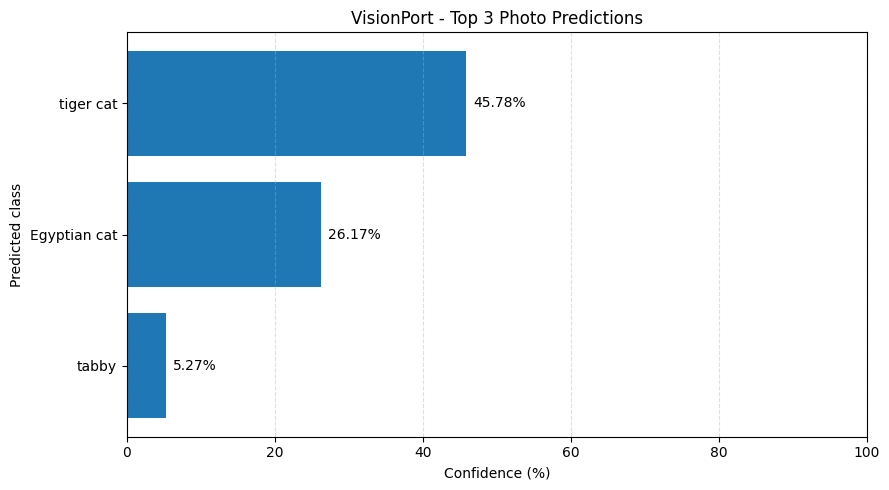

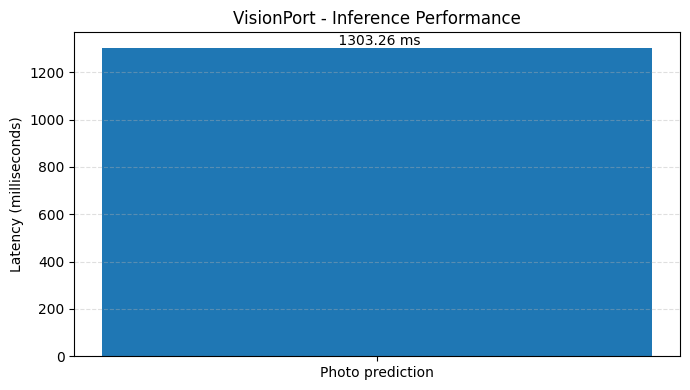

Both graphs generated and saved successfully!


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Check that Cell 3 produced prediction results
if "results" not in globals() or not results:
    print("Please run Cell 3 first and upload a photo.")
else:
    # Graph 1: Top-3 prediction confidence
    labels = [item["label"] for item in results]
    confidences = [item["confidence"] * 100 for item in results]

    plt.figure(figsize=(9, 5))
    bars = plt.barh(labels[::-1], confidences[::-1])
    plt.xlabel("Confidence (%)")
    plt.ylabel("Predicted class")
    plt.title("VisionPort - Top 3 Photo Predictions")
    plt.xlim(0, 100)
    plt.grid(axis="x", linestyle="--", alpha=0.4)

    for bar, value in zip(bars, confidences[::-1]):
        plt.text(
            min(value + 1, 95),
            bar.get_y() + bar.get_height() / 2,
            f"{value:.2f}%",
            va="center"
        )

    plt.tight_layout()
    plt.savefig("/content/VisionPort_prediction_confidence.png", dpi=150)
    plt.show()

    # Graph 2: Inference latency
    plt.figure(figsize=(7, 4))
    plt.bar(["Photo prediction"], [latency])
    plt.ylabel("Latency (milliseconds)")
    plt.title("VisionPort - Inference Performance")
    plt.grid(axis="y", linestyle="--", alpha=0.4)

    plt.text(
        0,
        latency,
        f" {latency:.2f} ms",
        ha="center",
        va="bottom"
    )

    plt.tight_layout()
    plt.savefig("/content/VisionPort_inference_latency.png", dpi=150)
    plt.show()

    print("Both graphs generated and saved successfully!")

In [ ]:
import os
import json
import pandas as pd
from pathlib import Path
from datetime import datetime

# Create folders
PROJECT = Path("/content/VisionPort")
LOG_DIR = PROJECT / "logs"
MODEL_DIR = PROJECT / "models"

LOG_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Collect actual prediction metrics from Cell 3
if "results" not in globals() or not results:
    print("Please run Cell 3 first to predict an uploaded photo.")
else:
    monitoring_data = {
        "timestamp": datetime.now().isoformat(),
        "model": "MobileNetV2-ImageNet",
        "predictions": results,
        "top_prediction": results[0]["label"],
        "top_confidence": results[0]["confidence"],
        "inference_latency_ms": float(latency)
    }

    # Save JSON metrics
    metrics_path = LOG_DIR / "monitoring_metrics.json"
    with open(metrics_path, "w") as f:
        json.dump(monitoring_data, f, indent=2)

    # Save prediction history as CSV
    history_path = LOG_DIR / "prediction_history.csv"
    rows = []

    for item in results:
        rows.append({
            "timestamp": monitoring_data["timestamp"],
            "predicted_class": item["label"],
            "confidence": item["confidence"],
            "inference_latency_ms": float(latency)
        })

    df = pd.DataFrame(rows)

    if history_path.exists():
        df.to_csv(history_path, mode="a", header=False, index=False)
    else:
        df.to_csv(history_path, index=False)

    print("Monitoring data saved!")
    print("JSON:", metrics_path)
    print("CSV:", history_path)
    display(df)

Monitoring data saved!
JSON: /content/VisionPort/logs/monitoring_metrics.json
CSV: /content/VisionPort/logs/prediction_history.csv


,timestamp,predicted_class,confidence,inference_latency_ms
0,2026-11-11T06:05:03.073712,tiger cat,0.457823,1303.257437
1,2026-11-11T06:05:03.073712,Egyptian cat,0.261693,1303.257437
2,2026-11-11T06:05:03.073712,tabby,0.052668,1303.257437


In [ ]:
from pathlib import Path

PROJECT = Path("/content/VisionPort")
PROJECT.mkdir(parents=True, exist_ok=True)

api_code = r'''
from io import BytesIO
import time

import numpy as np
import tensorflow as tf
from PIL import Image
from fastapi import FastAPI, UploadFile, File, HTTPException

app = FastAPI(title="VisionPort Photo Recognition API")

# Load pretrained photo-classification model
model = tf.keras.applications.MobileNetV2(weights="imagenet")

@app.get("/")
def home():
    return {
        "project": "VisionPort",
        "status": "running",
        "model": "MobileNetV2",
        "task": "photo classification"
    }

@app.get("/health")
def health():
    return {"status": "healthy"}

@app.post("/predict")
async def predict(file: UploadFile = File(...)):
    if file.content_type and not file.content_type.startswith("image/"):
        raise HTTPException(status_code=415, detail="Upload an image file.")

    content = await file.read()

    try:
        image = Image.open(BytesIO(content)).convert("RGB")
        image = image.resize((224, 224))
    except Exception:
        raise HTTPException(status_code=400, detail="Invalid image file.")

    array = np.asarray(image, dtype=np.float32)
    array = tf.keras.applications.mobilenet_v2.preprocess_input(array)
    array = np.expand_dims(array, axis=0)

    start = time.perf_counter()
    scores = model.predict(array, verbose=0)
    latency_ms = (time.perf_counter() - start) * 1000

    predictions = tf.keras.applications.mobilenet_v2.decode_predictions(
        scores, top=3
    )[0]

    return {
        "predictions": [
            {
                "label": label.replace("_", " "),
                "confidence": float(score)
            }
            for _, label, score in predictions
        ],
        "inference_latency_ms": round(latency_ms, 2)
    }
'''

api_path = PROJECT / "app.py"
api_path.write_text(api_code)

print("FastAPI application created:", api_path)
print("Endpoints: GET /, GET /health, POST /predict")

FastAPI application created: /content/VisionPort/app.py
Endpoints: GET /, GET /health, POST /predict


In [ ]:
import subprocess
import time
import requests

# Start the server
server = subprocess.Popen(
    [
        "uvicorn",
        "app:app",
        "--host", "127.0.0.1",
        "--port", "8000"
    ],
    cwd="/content/VisionPort",
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

# Wait for server startup
for attempt in range(20):
    try:
        response = requests.get(
            "http://127.0.0.1:8000/health",
            timeout=2
        )
        if response.ok:
            print("VisionPort API is running!")
            print(response.json())
            break
    except requests.RequestException:
        time.sleep(1)
else:
    print("API did not start. Check the app.py file and dependencies.")

VisionPort API is running!
{'status': 'healthy'}


In [ ]:
from google.colab import files

uploaded_api = files.upload()

image_names = [
    name for name in uploaded_api
    if name.lower().endswith((".jpg", ".jpeg", ".png", ".webp", ".bmp"))
]

if image_names:
    filename = image_names[0]

    with open(filename, "rb") as image_file:
        response = requests.post(
            "http://127.0.0.1:8000/predict",
            files={"file": (filename, image_file, "image/jpeg")},
            timeout=120
        )

    print("HTTP status:", response.status_code)
    print(response.json())
else:
    print("Please upload a JPG, PNG, or WEBP photo.")

Saving Ginger Cat Amid Greenery.png to Ginger Cat Amid Greenery (1).png
HTTP status: 200
{'predictions': [{'label': 'tiger cat', 'confidence': 0.4578232765197754}, {'label': 'Egyptian cat', 'confidence': 0.26169317960739136}, {'label': 'tabby', 'confidence': 0.05266807973384857}], 'inference_latency_ms': 2646.79}
